# 03_features：標籤、特徵與 triage

設定與協定見 `setup.yaml`；程式在 `src/s03_features.py`。預設 `RUN = False` 只讀已存的結果。

In [1]:
import os, sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT); sys.path.insert(0, str(ROOT))
import pandas as pd
from IPython.display import Image, Markdown, display
pd.set_option("display.max_columns", 40); pd.set_option("display.width", 200)
R = ROOT / "results"
def show(name, n=60):
    p = R / f"{name}.csv"
    display(Markdown(f"**{name}**")); display(pd.read_csv(p, encoding="utf-8-sig").head(n)) if p.exists() else print("缺", name)
def fig(name, w=800):
    p = R / "figures" / name
    display(Image(filename=str(p), width=w)) if p.exists() else print("缺圖", name)

In [2]:
RUN = False
if RUN:
    from src import s03_features
    s03_features.main()

**03_triage**

,特徵,角色,G1 截斷相同,G1 安慰劑 IC,G1 安慰劑消失,IC,lo,hi,p,ICIR,同號 fold 比例,IC fwd5,IC fwd60,Q1,Q5,五分位單調 ρ,頂底價差/20日,20 日排名自相關,BH q,G1,G2,G3,G4,G5,決定
0,peer_ret20,signal,True,-0.014346,True,-0.018564,-0.033835,-0.003293,1.719067e-02,-0.132869,0.76,-0.003997,-0.009701,0.009072,0.010802,0.6,0.001730,-0.014103,2.656739e-02,True,True,False,False,True,REVISE
1,peer_ret60,signal,True,-0.013010,True,-0.022444,-0.040485,-0.004402,1.475861e-02,-0.154553,0.72,-0.016445,-0.014989,0.008251,0.011089,0.7,0.002838,0.495286,2.508964e-02,True,True,False,False,True,REVISE
2,peer_ret5,signal,True,-0.013334,False,0.004081,-0.004294,0.012455,3.395526e-01,0.030777,0.56,-0.006962,-0.000251,0.007565,0.011030,0.9,0.003465,0.003132,3.848263e-01,False,False,False,False,False,STOP
3,peer_gap20,signal,True,-0.007875,True,0.015608,0.006024,0.025192,1.413268e-03,0.190880,0.80,0.021038,-0.010754,0.012256,0.009271,-0.9,0.002985,-0.017061,3.003195e-03,True,True,False,False,True,REVISE
4,peer_breadth20,signal,True,-0.003335,True,-0.003709,-0.017171,0.009754,5.892191e-01,-0.030175,0.52,0.005774,0.005960,0.007754,0.010759,0.7,0.003005,-0.025189,6.260452e-01,True,False,False,False,False,STOP
5,leader_ret20,signal,True,-0.012739,True,-0.017136,-0.030012,-0.004261,9.090086e-03,-0.145163,0.72,-0.002810,-0.009939,0.008640,0.011259,0.7,0.002619,-0.004610,1.717016e-02,True,True,False,False,True,REVISE
6,peer_tight,state,True,-0.027111,False,-0.026702,-0.042226,-0.011179,7.476105e-04,-0.217184,0.80,-0.013389,-0.042210,0.011302,0.004927,-0.7,0.006375,0.905387,1.815626e-03,False,True,False,False,True,REVISE
7,ret20,signal,True,-0.001684,True,-0.027397,-0.041777,-0.013018,1.881907e-04,-0.220121,0.76,-0.023268,0.002209,0.007966,0.012356,0.9,0.004390,-0.019609,5.332070e-04,True,True,False,False,True,REVISE
8,rev5,signal,True,-0.002508,True,-0.009014,-0.017028,-0.001000,2.747843e-02,-0.080963,0.80,-0.041585,0.003693,0.008484,0.011553,1.0,0.003069,-0.018896,3.892777e-02,True,True,True,False,True,REVISE
9,mom120_20,signal,True,0.009188,True,0.008911,-0.006498,0.024321,2.570268e-01,0.070508,0.64,0.002386,0.026165,0.002992,0.015095,1.0,0.012103,0.773513,3.121040e-01,True,False,True,False,False,STOP


**03_truncation**

,特徵,比對格數,最大絕對差,不一致格數
0,peer_ret20,1106127,0.0,0
1,peer_ret60,1106136,0.0,0
2,peer_ret5,1106132,0.0,0
3,peer_gap20,1104484,0.0,0
4,peer_breadth20,1106127,0.0,0
5,leader_ret20,1105829,0.0,0
6,peer_tight,1106140,0.0,0
7,ret20,1193240,0.0,0
8,rev5,1194783,0.0,0
9,mom120_20,1184740,0.0,0


**03_mechanism**

,特徵,原始 IC,安慰劑 IC（移 21 日）,控制 beta、規模後 IC,控制後 lo,控制後 hi,再控制本股 ret20 後 IC,lo,hi
0,overnight20,-0.058253,-0.036881,-0.053624,-0.065205,-0.042043,NaN,NaN,NaN
1,max_ret20,-0.064711,-0.050430,-0.066932,-0.080303,-0.053560,NaN,NaN,NaN
2,vol60,-0.071132,-0.065594,-0.080644,-0.100069,-0.061218,NaN,NaN,NaN
3,peer_ret20,-0.018564,-0.014346,-0.009220,-0.020340,0.001900,-0.003692,-0.012612,0.005228
4,peer_gap20,0.015608,-0.007875,0.013842,0.004898,0.022786,0.003258,-0.004182,0.010697


**03_regime**

,特徵,狀態,IC,lo,hi,日數
0,overnight20,低波動,-0.067862,-0.087021,-0.048703,1381
1,overnight20,中波動,-0.058717,-0.077374,-0.040060,1079
2,overnight20,高波動,-0.036805,-0.061106,-0.012504,642
3,overnight20,多頭,-0.058734,-0.073649,-0.043820,2439
4,overnight20,空頭,-0.056484,-0.083976,-0.028992,663
5,max_ret20,低波動,-0.080270,-0.103753,-0.056786,1381
6,max_ret20,中波動,-0.075783,-0.098714,-0.052851,1079
7,max_ret20,高波動,-0.012635,-0.048394,0.023124,642
8,max_ret20,多頭,-0.077855,-0.095777,-0.059933,2439
9,max_ret20,空頭,-0.016357,-0.056260,0.023545,663


{'features': ['peer_ret20', 'peer_ret60', 'peer_gap20', 'leader_ret20', 'peer_tight', 'ret20', 'rev5', 'near_high250', 'vol60', 'max_ret20', 'overnight20', 'volume_surge', 'adv60', 'mkt_vol20', 'mkt_trend', 'disp20'], 'dropped_as_duplicate': {}, 'stopped': ['peer_ret5', 'peer_breadth20', 'mom120_20', 'beta60']}


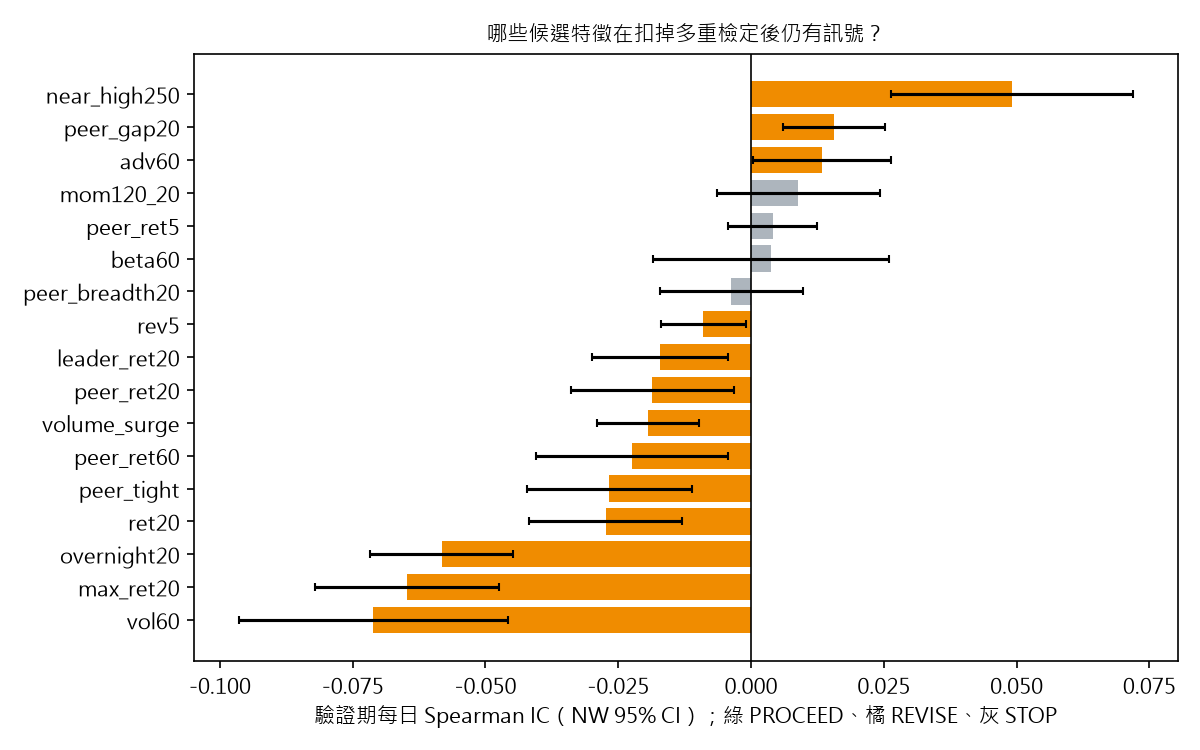

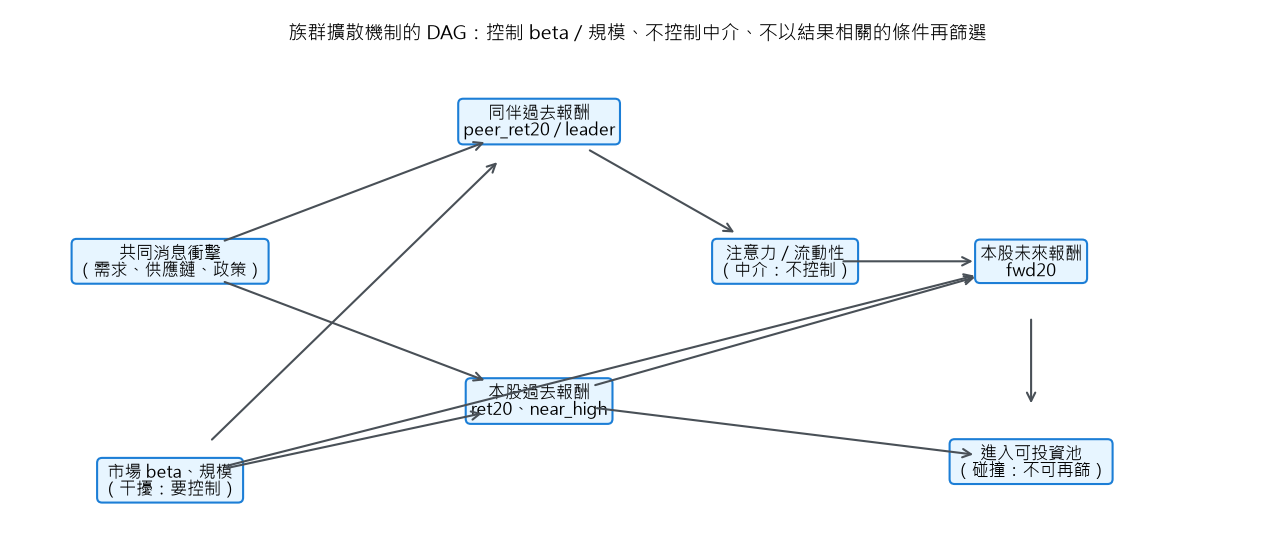

In [3]:
show("03_triage"); show("03_truncation"); show("03_mechanism"); show("03_regime")
print(json.loads((R / "03_model_features.json").read_text(encoding="utf-8")))
fig("03_triage_ic.png"); fig("03_dag.png")